In [12]:
# ============================================================
# STEP 1: IMPORT LIBRARIES AND LOAD THE DATASET
# ============================================================

# Import libraries for data analysis
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for machine learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Import KNN and Decision Tree models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the dataset
df = pd.read_csv('data/penguins_lter.csv')

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (344, 17)


,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0708,1,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A1,Yes,11/11/07,39.1,18.7,181.0,3750.0,MALE,NaN,NaN,Not enough blood for isotopes.
1,PAL0708,2,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A2,Yes,11/11/07,39.5,17.4,186.0,3800.0,FEMALE,8.94956,-24.69454,NaN
2,PAL0708,3,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A1,Yes,11/16/07,40.3,18.0,195.0,3250.0,FEMALE,8.36821,-25.33302,NaN
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,11/16/07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
4,PAL0708,5,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N3A1,Yes,11/16/07,36.7,19.3,193.0,3450.0,FEMALE,8.76651,-25.32426,NaN



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   studyName            344 non-null    object 
 1   Sample Number        344 non-null    int64  
 2   Species              344 non-null    object 
 3   Region               344 non-null    object 
 4   Island               344 non-null    object 
 5   Stage                344 non-null    object 
 6   Individual ID        344 non-null    object 
 7   Clutch Completion    344 non-null    object 
 8   Date Egg             344 non-null    object 
 9   Culmen Length (mm)   342 non-null    float64
 10  Culmen Depth (mm)    342 non-null    float64
 11  Flipper Length (mm)  342 non-null    float64
 12  Body Mass (g)        342 non-null    float64
 13  Sex                  334 non-null    object 
 14  Delta 15 N (o/oo)    330 non-null    float64
 15  Delta 13 C (o/oo) 

In [13]:
# STEP 2: DATASET UNDERSTANDING
# ============================================================

# Display statistical summary
print("Statistical Summary:")
display(df.describe())

# Display species distribution
print("\nSpecies Distribution:")
print(df['Species'].value_counts())

# Check duplicate records
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Display number of unique species
print("\nNumber of Species:", df['Species'].nunique())

Statistical Summary:


,Sample Number,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Delta 15 N (o/oo),Delta 13 C (o/oo)
count,344.000000,342.000000,342.000000,342.000000,342.000000,330.000000,331.000000
mean,63.151163,43.921930,17.151170,200.915205,4201.754386,8.733382,-25.686292
std,40.430199,5.459584,1.974793,14.061714,801.954536,0.551770,0.793961
min,1.000000,32.100000,13.100000,172.000000,2700.000000,7.632200,-27.018540
25%,29.000000,39.225000,15.600000,190.000000,3550.000000,8.299890,-26.320305
50%,58.000000,44.450000,17.300000,197.000000,4050.000000,8.652405,-25.833520
75%,95.250000,48.500000,18.700000,213.000000,4750.000000,9.172123,-25.062050
max,152.000000,59.600000,21.500000,231.000000,6300.000000,10.025440,-23.787670



Species Distribution:
Species
Adelie Penguin (Pygoscelis adeliae)          152
Gentoo penguin (Pygoscelis papua)            124
Chinstrap penguin (Pygoscelis antarctica)     68
Name: count, dtype: int64

Number of Duplicate Rows: 0

Dataset Columns:
['studyName', 'Sample Number', 'Species', 'Region', 'Island', 'Stage', 'Individual ID', 'Clutch Completion', 'Date Egg', 'Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Body Mass (g)', 'Sex', 'Delta 15 N (o/oo)', 'Delta 13 C (o/oo)', 'Comments']

Number of Species: 3


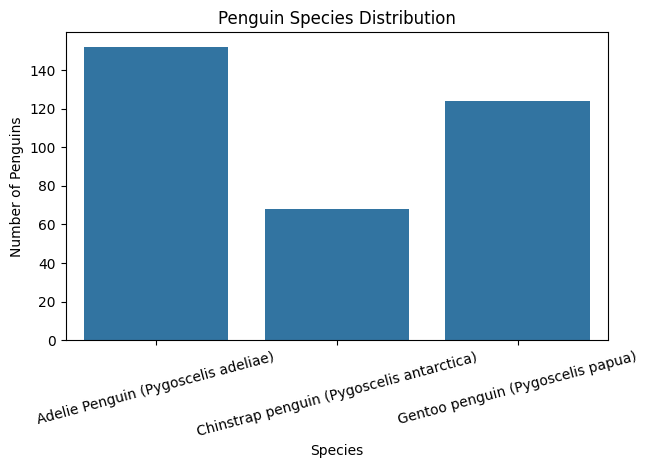

In [18]:
# STEP 3: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Select numerical features for classification
features = [
    'Culmen Length (mm)',
    'Culmen Depth (mm)',
    'Flipper Length (mm)',
    'Body Mass (g)'
]

# ------------------------------------------------------------
# 3.1: VISUALIZE SPECIES DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='Species')

plt.title("Penguin Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Penguins")
plt.xticks(rotation=15)

plt.show()




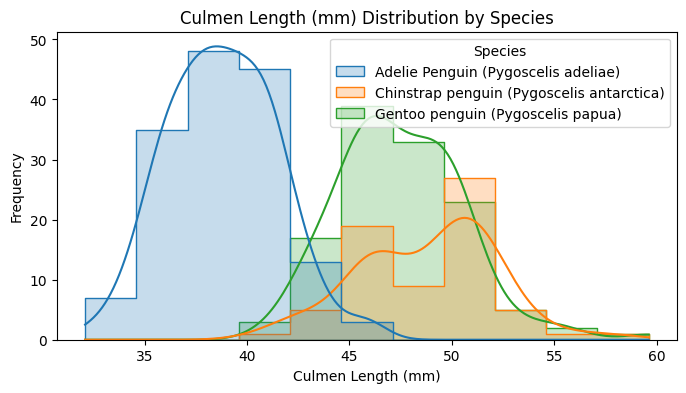

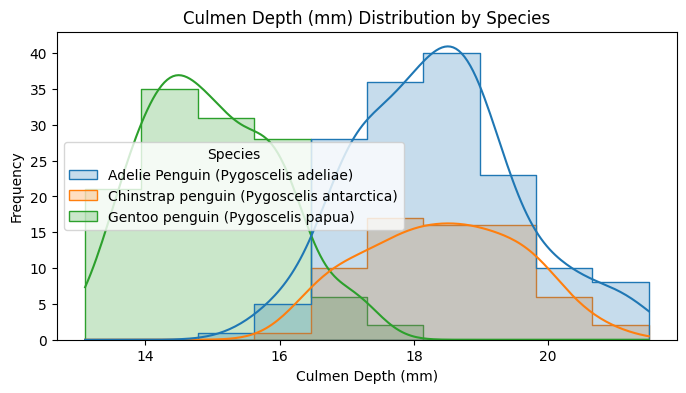

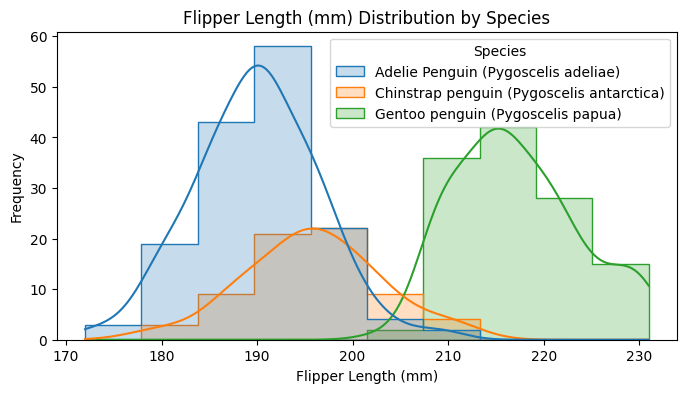

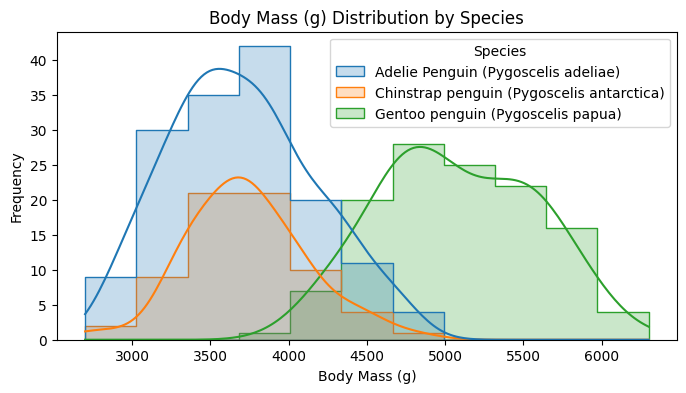

In [16]:
# ------------------------------------------------------------
# 3.2: VISUALIZE FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

# Plot each numerical feature by species
for feature in features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue='Species',
        kde=True,
        element='step'
    )

    plt.title(f"{feature} Distribution by Species")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.show()

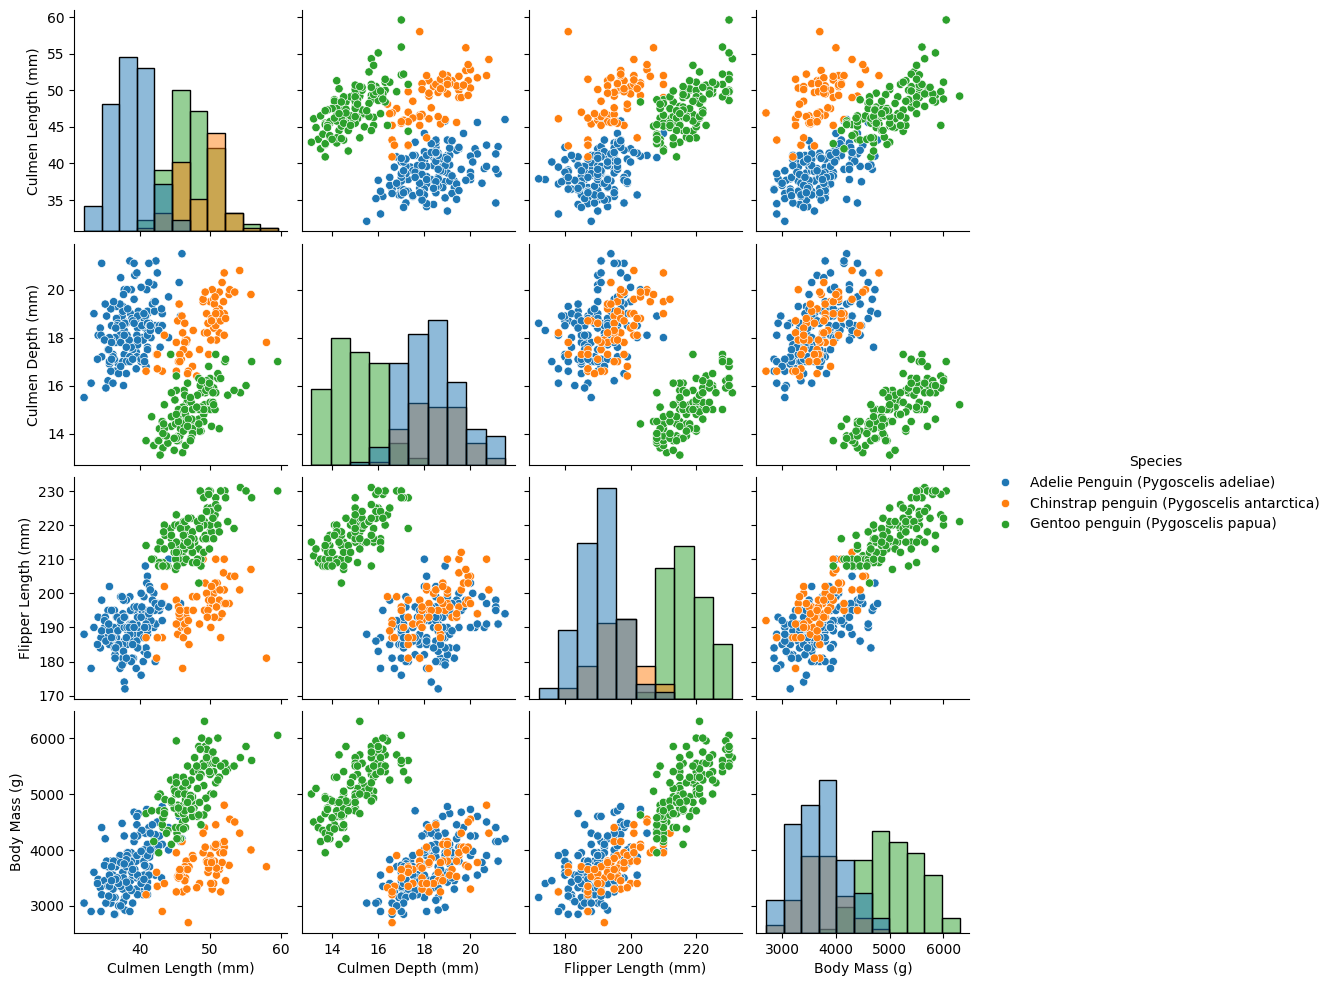

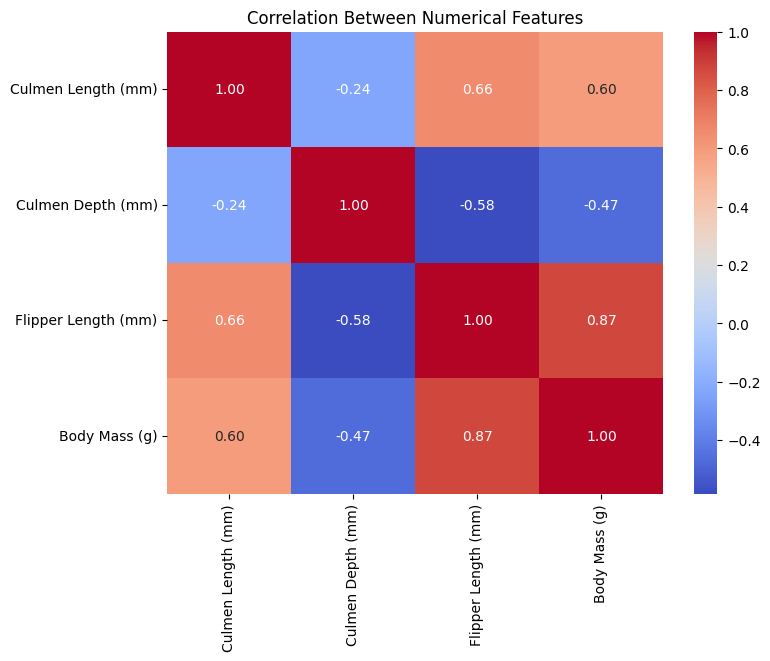

In [19]:
# ------------------------------------------------------------
# 3.3: PAIR PLOT OF NUMERICAL FEATURES
# ------------------------------------------------------------

# Remove missing values for visualization
eda_df = df[features + ['Species']].dropna()

# Display relationships between features
sns.pairplot(
    eda_df,
    hue='Species',
    diag_kind='hist'
)

plt.show()


# ------------------------------------------------------------
# 3.4: CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Numerical Features")

plt.show()

In [20]:
# STEP 4: DATA PREPROCESSING
# ============================================================

# Select input features
X = df[features]

# Select target variable
y = df['Species']

# Remove rows with missing target values
valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Split dataset into training and testing sets
# 80% training data and 20% testing data
# Stratify maintains species proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display training and testing shapes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Display species distribution in training data
print("\nTraining Species Distribution:")
print(y_train.value_counts())

# Display species distribution in testing data
print("\nTesting Species Distribution:")
print(y_test.value_counts())

Training Data Shape: (275, 4)
Testing Data Shape: (69, 4)

Training Species Distribution:
Species
Adelie Penguin (Pygoscelis adeliae)          122
Gentoo penguin (Pygoscelis papua)             99
Chinstrap penguin (Pygoscelis antarctica)     54
Name: count, dtype: int64

Testing Species Distribution:
Species
Adelie Penguin (Pygoscelis adeliae)          30
Gentoo penguin (Pygoscelis papua)            25
Chinstrap penguin (Pygoscelis antarctica)    14
Name: count, dtype: int64


In [21]:
# ============================================================
# STEP 5: MODEL BUILDING AND TRAINING
# ============================================================

# ------------------------------------------------------------
# MODEL 1: K-NEAREST NEIGHBORS (KNN)
# ------------------------------------------------------------

# Pipeline steps:
# 1. Fill missing values using median
# 2. Standardize numerical features
# 3. Train KNN classifier with 5 neighbors

knn_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])


# ------------------------------------------------------------
# MODEL 2: DECISION TREE CLASSIFIER
# ------------------------------------------------------------

# Pipeline steps:
# 1. Fill missing values using median
# 2. Train Decision Tree classifier
# Feature scaling is not required for Decision Tree

decision_tree_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(random_state=42))
])


# ------------------------------------------------------------
# TRAIN BOTH MODELS
# ------------------------------------------------------------

# Train KNN model
knn_model.fit(X_train, y_train)

# Train Decision Tree model
decision_tree_model.fit(X_train, y_train)

# Display training status
print("KNN model trained successfully!")
print("Decision Tree model trained successfully!")


# ------------------------------------------------------------
# STORE MODELS IN A DICTIONARY
# ------------------------------------------------------------

models = {
    'KNN': knn_model,
    'Decision Tree': decision_tree_model
}


KNN model trained successfully!
Decision Tree model trained successfully!


In [22]:
# STEP 6: MODEL EVALUATION
# ============================================================

# Create an empty list to store model results
results = []

# Evaluate each model
for name, model in models.items():

    # Predict species using test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate weighted precision
    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    # Calculate weighted recall
    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    # Calculate weighted F1-score
    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    # Display classification report
    print("\n====================================")
    print("MODEL:", name)
    print("====================================")

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display model evaluation results
print("\nModel Evaluation Results:")
display(results_df.round(4))



MODEL: KNN
                                           precision    recall  f1-score   support

      Adelie Penguin (Pygoscelis adeliae)       1.00      1.00      1.00        30
Chinstrap penguin (Pygoscelis antarctica)       1.00      1.00      1.00        14
        Gentoo penguin (Pygoscelis papua)       1.00      1.00      1.00        25

                                 accuracy                           1.00        69
                                macro avg       1.00      1.00      1.00        69
                             weighted avg       1.00      1.00      1.00        69


MODEL: Decision Tree
                                           precision    recall  f1-score   support

      Adelie Penguin (Pygoscelis adeliae)       1.00      0.97      0.98        30
Chinstrap penguin (Pygoscelis antarctica)       1.00      1.00      1.00        14
        Gentoo penguin (Pygoscelis papua)       0.96      1.00      0.98        25

                                 accuracy       

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,1.0000,1.0000,1.0000,1.0000
1,Decision Tree,0.9855,0.9861,0.9855,0.9855


KNN vs Decision Tree:


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,1.0000,1.0000,1.0000,1.0000
1,Decision Tree,0.9855,0.9861,0.9855,0.9855


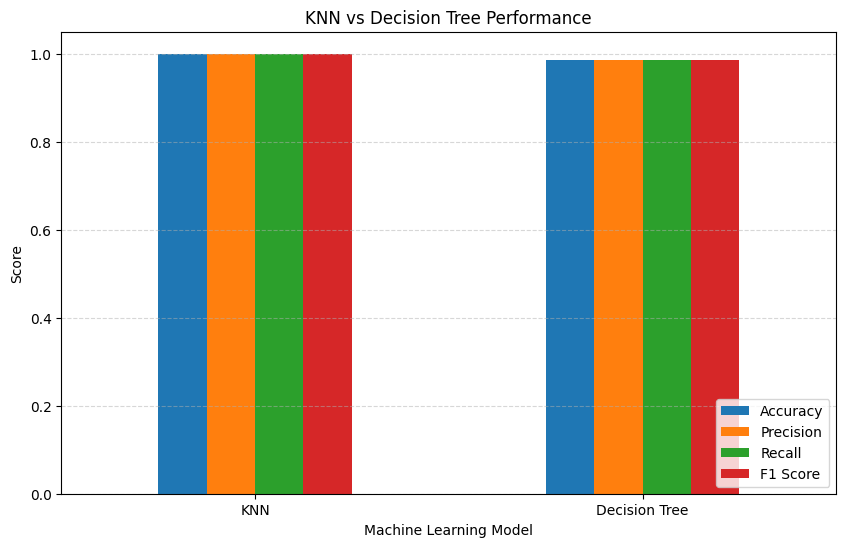

Best Model Based on F1 Score: KNN


In [23]:
# ============================================================
# STEP 7: MODEL PERFORMANCE COMPARISON
# ============================================================

# Display comparison table
print("KNN vs Decision Tree:")
display(results_df.round(4))


# ------------------------------------------------------------
# VISUALIZE PERFORMANCE METRICS
# ------------------------------------------------------------

# Set model names as index
comparison_df = results_df.set_index('Model')

# Create bar chart for metric comparison
comparison_df.plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("KNN vs Decision Tree Performance")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


# ------------------------------------------------------------
# IDENTIFY THE BEST MODEL BASED ON F1 SCORE
# ------------------------------------------------------------

best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(),
    'Model'
]

print("Best Model Based on F1 Score:", best_model_name)


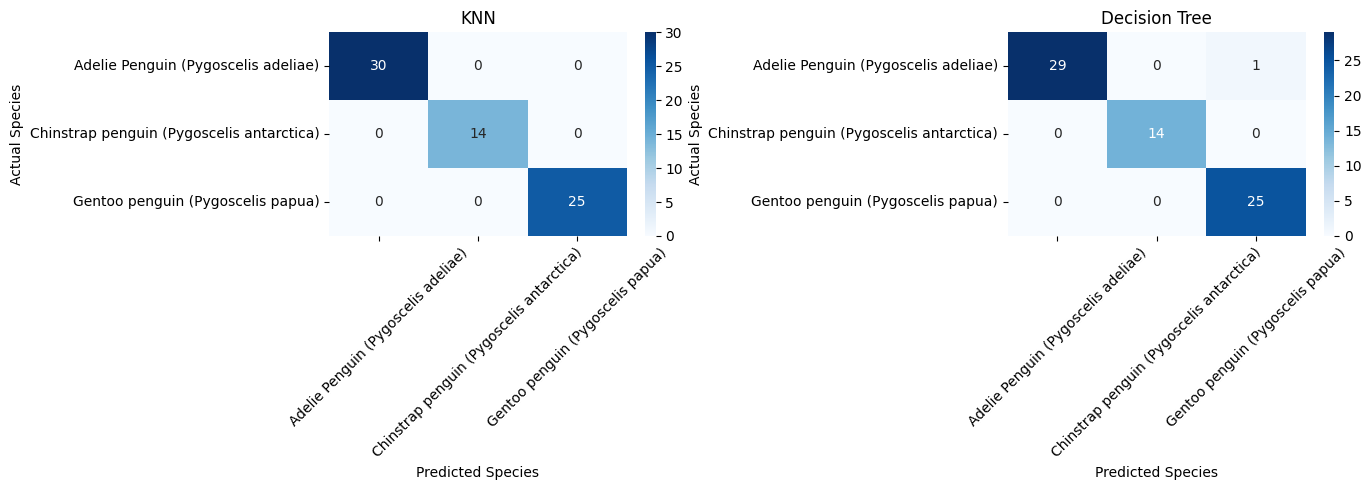

In [25]:
# ============================================================
# STEP 8: CONFUSION MATRICES
# ============================================================

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Generate confusion matrix for each model
for ax, (name, model) in zip(axes, models.items()):

    # Predict species
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    # Add titles and labels
    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

# Adjust layout
plt.tight_layout()

# Display confusion matrices
plt.show()



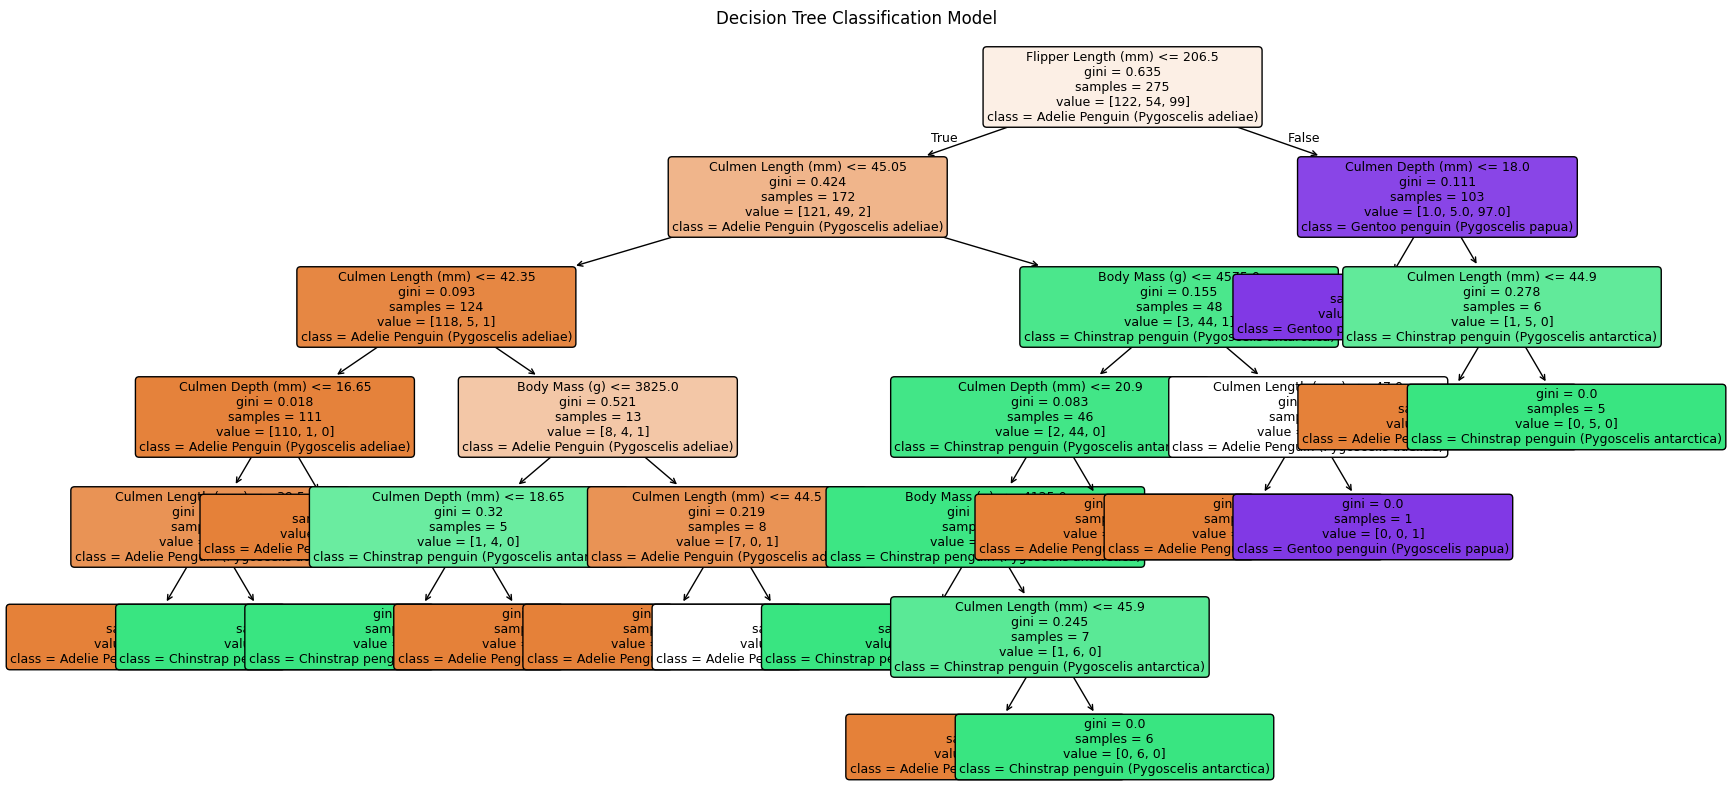

In [26]:
# ------------------------------------------------------------
# VISUALIZE THE TRAINED DECISION TREE
# ------------------------------------------------------------

# Extract trained Decision Tree classifier
trained_tree = decision_tree_model.named_steps['classifier']

# Plot the decision tree
plt.figure(figsize=(20, 10))

plot_tree(
    trained_tree,
    feature_names=features,
    class_names=trained_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classification Model")
plt.show()



In [27]:
# ============================================================
# STEP 9: CROSS-VALIDATION AND FINAL COMPARISON
# ============================================================

# Create an empty list for cross-validation results
cv_results = []

# Perform 5-fold cross-validation for each model
for name, model in models.items():

    # Calculate cross-validation accuracy scores
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='accuracy'
    )

    # Calculate mean accuracy
    mean_score = scores.mean()

    # Calculate standard deviation
    std_score = scores.std()

    # Store cross-validation results
    cv_results.append({
        'Model': name,
        'CV Mean Accuracy': mean_score,
        'CV Standard Deviation': std_score
    })

    # Display cross-validation results
    print("\nModel:", name)
    print("Cross-Validation Scores:", np.round(scores, 4))
    print("Mean CV Accuracy:", round(mean_score, 4))
    print("Standard Deviation:", round(std_score, 4))


Model: KNN
Cross-Validation Scores: [0.971  0.9855 0.9855 1.     0.9853]
Mean CV Accuracy: 0.9855
Standard Deviation: 0.0092

Model: Decision Tree
Cross-Validation Scores: [0.9565 0.9855 0.9565 0.9855 0.9265]
Mean CV Accuracy: 0.9621
Standard Deviation: 0.022


In [28]:
# ------------------------------------------------------------
# CREATE FINAL COMPARISON TABLE
# ------------------------------------------------------------

# Convert cross-validation results into DataFrame
cv_df = pd.DataFrame(cv_results)

# Combine test metrics and cross-validation results
final_comparison = pd.merge(
    results_df,
    cv_df,
    on='Model'
)

# Display final comparison table
print("\nFINAL MODEL COMPARISON")

display(final_comparison.round(4))


# ------------------------------------------------------------
# FINAL PROJECT CONCLUSION
# ------------------------------------------------------------

# Identify best model based on weighted F1-score
best_model = final_comparison.loc[
    final_comparison['F1 Score'].idxmax()
]

print("\n================================")
print("PROJECT CONCLUSION")
print("================================")

print("Best Performing Model:", best_model['Model'])

print("Test Accuracy:",
      round(best_model['Accuracy'], 4))

print("Test Precision:",
      round(best_model['Precision'], 4))

print("Test Recall:",
      round(best_model['Recall'], 4))

print("Test F1 Score:",
      round(best_model['F1 Score'], 4))

print("Mean CV Accuracy:",
      round(best_model['CV Mean Accuracy'], 4))

print("\nKNN and Decision Tree comparison completed!")


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,CV Mean Accuracy,CV Standard Deviation
0,KNN,1.0000,1.0000,1.0000,1.0000,0.9855,0.0092
1,Decision Tree,0.9855,0.9861,0.9855,0.9855,0.9621,0.0220



PROJECT CONCLUSION
Best Performing Model: KNN
Test Accuracy: 1.0
Test Precision: 1.0
Test Recall: 1.0
Test F1 Score: 1.0
Mean CV Accuracy: 0.9855

KNN and Decision Tree comparison completed!
